In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import src.helper
import xarray as xr

In [2]:
ds = xr.open_dataset(
    "/media/sf_VM_Folder/data/ERA5/data.grib", engine="cfgrib"
)  # requires the installation of the cfgrib package

/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/cfgrib/xarray_plugin.py:131: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


In [3]:
ds

<xarray.Dataset> Size: 214MB
Dimensions:        (time: 2190, latitude: 101, longitude: 121)
Coordinates:
    number         int64 8B ...
  * time           (time) datetime64[ns] 18kB 2017-01-01 ... 2019-12-31T12:00:00
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
  * latitude       (latitude) float64 808B -55.0 -55.25 -55.5 ... -79.75 -80.0
  * longitude      (longitude) float64 968B -60.0 -59.75 -59.5 ... -30.25 -30.0
    valid_time     (time) datetime64[ns] 18kB ...
Data variables:
    u              (time, latitude, longitude) float32 107MB ...
    v              (time, latitude, longitude) float32 107MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-05-27T18:23 GRIB to CDM+CF via cfgrib-0.9.1...

In [4]:
# ds_subset = ds.sel(lat=ds.latitude.query("-72 <= lat <= -60"), lon=ds.longitude.query("-60 <= lon <= -30"))
wind = ds.sel(latitude=slice(-60, -72), longitude=slice(-60, -30))

In [5]:
wind

<xarray.Dataset> Size: 104MB
Dimensions:        (time: 2190, latitude: 49, longitude: 121)
Coordinates:
    number         int64 8B ...
  * time           (time) datetime64[ns] 18kB 2017-01-01 ... 2019-12-31T12:00:00
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
  * latitude       (latitude) float64 392B -60.0 -60.25 -60.5 ... -71.75 -72.0
  * longitude      (longitude) float64 968B -60.0 -59.75 -59.5 ... -30.25 -30.0
    valid_time     (time) datetime64[ns] 18kB ...
Data variables:
    u              (time, latitude, longitude) float32 52MB ...
    v              (time, latitude, longitude) float32 52MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-05-27T18:23 GRIB to CDM+CF via cfgrib-0.9.1...

In [6]:
wind.isel(time=0)

<xarray.Dataset> Size: 49kB
Dimensions:        (latitude: 49, longitude: 121)
Coordinates:
    number         int64 8B ...
    time           datetime64[ns] 8B 2017-01-01
    step           timedelta64[ns] 8B ...
    isobaricInhPa  float64 8B ...
  * latitude       (latitude) float64 392B -60.0 -60.25 -60.5 ... -71.75 -72.0
  * longitude      (longitude) float64 968B -60.0 -59.75 -59.5 ... -30.25 -30.0
    valid_time     datetime64[ns] 8B ...
Data variables:
    u              (latitude, longitude) float32 24kB ...
    v              (latitude, longitude) float32 24kB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-05-27T18:23 GRIB to CDM+CF via cfgrib-0.9.1...

In [7]:
# ds_subset.plot.scatter()

In [8]:
lat = wind.variables["latitude"][:]  # latitude grid points
lon = wind.variables["longitude"][:]  # longitude grid points
# depth = ds.variables['h'][:] # depth grid points

In [9]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-60, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    lathelp = np.arange(-75, -60, 5)
    gl.ylocator = mticker.FixedLocator(lathelp)
    lonhelp = np.arange(-80, -10, 10)
    gl.xlocator = mticker.FixedLocator(lonhelp)

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

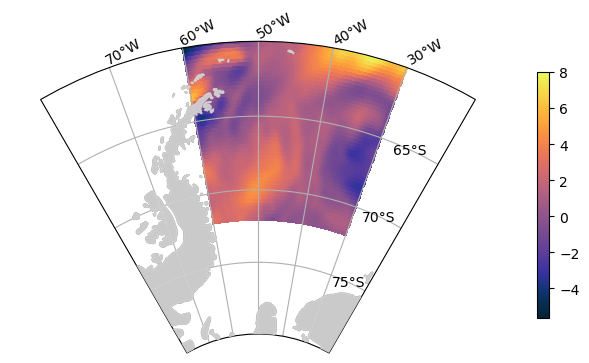

In [10]:
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon,
    lat,
    wind.isel(time=0).variables["u"],
    transform=ccrs.PlateCarree(),
    cmap=cm.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4);

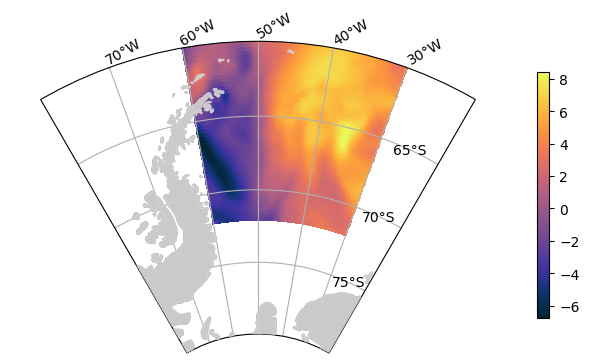

In [11]:
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    lon,
    lat,
    wind.isel(time=0).variables["v"],
    transform=ccrs.PlateCarree(),
    cmap=cm.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4);

In [12]:
for dim in [lon, lat, wind.isel(time=0).variables["u"]]:
    print(dim.shape)

(121,)
(49,)
(49, 121)


In [13]:
mooring_names = ["A", "B", "C", "D", "E", "F", "G"]
list_of_moorings = src.helper.load_pickle(name="../data/mooring/list_of_moorings.pkl")
width_in_lon = 1
height_in_lat = 0.5

mooring_bins = {}
for name, mooring in zip(mooring_names, list_of_moorings):
    boxlats = np.array(
        [mooring.location.lat + height_in_lat / 2, mooring.location.lat - height_in_lat / 2]
    )
    boxlons = np.array(
        [mooring.location.lon - width_in_lon / 2, mooring.location.lon + width_in_lon / 2]
    )

    mooring_bins[name] = {"lat": boxlats, "lon": boxlons}

In [14]:
for name, bounds in mooring_bins.items():
    print(name, bounds)

A {'lat': array([-63.1532, -63.6532]), 'lon': array([-52.787, -51.787])}
B {'lat': array([-63.2645, -63.7645]), 'lon': array([-52.1357, -51.1357])}
C {'lat': array([-63.406, -63.906]), 'lon': array([-51.3113, -50.3113])}
D {'lat': array([-63.5283, -64.0283]), 'lon': array([-50.5897, -49.5897])}
E {'lat': array([-63.667, -64.167]), 'lon': array([-49.7682, -48.7682])}
F {'lat': array([-63.8165, -64.3165]), 'lon': array([-48.8805, -47.8805])}
G {'lat': array([-63.9657, -64.4657]), 'lon': array([-47.9903, -46.9903])}


In [15]:
def setup_transect_view(fig):
    ax = fig.add_subplot(111, projection=ccrs.SouthPolarStereo(central_longitude=-50))
    # Limit the map to -60 degrees latitude and below.
    ax.set_extent([-54, -46, -64.5, -62.6], crs=ccrs.PlateCarree())
    # ax.set_extent([-55, -45, -65, -62], ccrs.PlateCarree())
    ax.gridlines(draw_labels=True)
    return ax

In [16]:
# fig = plt.figure(figsize=(6, 6))
# ax = setup_transect_view(fig)
# im = ax.pcolormesh(lon, lat, wind.isel(time=0).variables['v'], transform=ccrs.PlateCarree(), cmap = cm.cm.thermal, shading = "nearest")
# ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder = 10)
# for name, mooring in zip(mooring_names, list_of_moorings):
#     ax.plot(mooring.location.lon,mooring.location.lat, "k.", ms = 20,  transform=ccrs.PlateCarree())

# for mooring in list_of_moorings:
#     patch = mpatches.Rectangle(
#             xy=[mooring.location.lon-width_in_lon/2, mooring.location.lat-height_in_lat/2],
#             width=width_in_lon, height=height_in_lat,
#             facecolor='none', edgecolor='k',
#             transform=ccrs.PlateCarree()
#         )
#     assert np.all(patch.get_center() == (mooring.location.lon, mooring.location.lat))
#     ax.add_patch(patch)

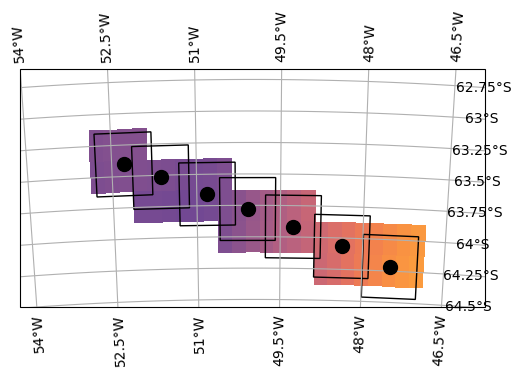

In [17]:
fig = plt.figure(figsize=(6, 6))
ax = setup_transect_view(fig)

ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)

for name, bounds in mooring_bins.items():
    wind_at_mooring = wind.sel(
        latitude=slice(bounds["lat"][0], bounds["lat"][1]),
        longitude=slice(bounds["lon"][0], bounds["lon"][1]),
    )
    boxlat = wind_at_mooring.variables["latitude"][:]  # latitude grid points
    boxlon = wind_at_mooring.variables["longitude"][:]  # longitude grid points

    assert boxlat.size != 1
    assert boxlon.size != 1

    # Compute monthly statistics averaged over space
    im = ax.pcolormesh(
        boxlon,
        boxlat,
        wind_at_mooring.isel(time=0).variables["v"],
        vmin=-6,
        vmax=8,
        transform=ccrs.PlateCarree(),
        cmap=cm.cm.thermal,
        shading="nearest",
    )

for name, mooring in zip(mooring_names, list_of_moorings):
    ax.plot(mooring.location.lon, mooring.location.lat, "k.", ms=20, transform=ccrs.PlateCarree())

for mooring in list_of_moorings:
    patch = mpatches.Rectangle(
        xy=[mooring.location.lon - width_in_lon / 2, mooring.location.lat - height_in_lat / 2],
        width=width_in_lon,
        height=height_in_lat,
        facecolor="none",
        edgecolor="k",
        transform=ccrs.PlateCarree(),
    )
    assert np.all(patch.get_center() == (mooring.location.lon, mooring.location.lat))
    ax.add_patch(patch)

In [18]:
# Create an empty dictionary to store results
results = {}
for name, bounds in mooring_bins.items():
    wind_at_mooring = wind.sel(
        latitude=slice(bounds["lat"][0], bounds["lat"][1]),
        longitude=slice(bounds["lon"][0], bounds["lon"][1]),
    )

    # complex_wind = wind_at_mooring.assign(wind = wind_at_mooring.u + 1j * wind_at_mooring.v)
    # Compute monthly statistics averaged over space
    wind_mean = wind_at_mooring.resample(time="1D").mean(dim=["latitude", "longitude", "time"])
    wind_std = wind_at_mooring.resample(time="1D").std(dim=["latitude", "longitude", "time"])

    results[name] = {"mean": wind_mean, "std": wind_std}

In [19]:
# for var in wind_mean.variables:
#     print(var)
# print('')
# for var in wind_std.variables:
#     print(var)

In [20]:
mean_wind_df = pd.DataFrame(index=wind_mean["time"])
std_wind_df = pd.DataFrame(index=wind_std.variables["time"].values)
for name, result in results.items():
    mean_wind_df[name] = result["mean"].variables["u"] + 1j * result["mean"].variables["v"]
    std_wind_df[name] = result["std"].variables["u"] + 1j * result["std"].variables["v"]

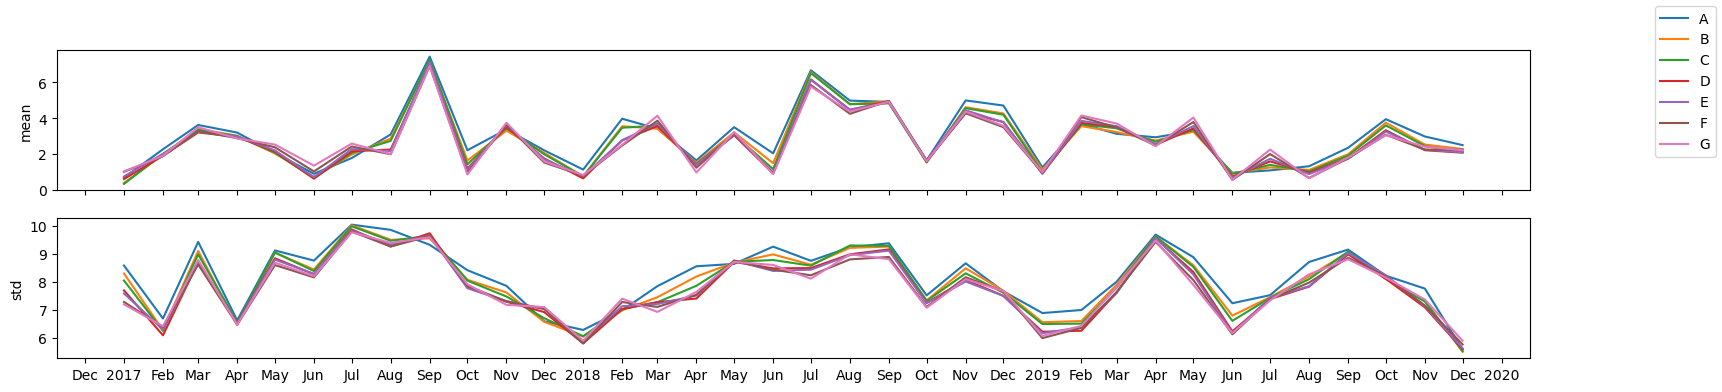

In [21]:
fig, ax = plt.subplots(nrows=2, figsize=(19, 4), sharex=True)
for col in mean_wind_df.columns:
    ax[0].plot(mean_wind_df.index, mean_wind_df[col].abs(), label=col)
    ax[1].plot(std_wind_df.index, std_wind_df[col].abs())  # , label = col)
fig.legend()
ax[0].set_ylabel("mean")
ax[1].set_ylabel("std")
locator = mdates.AutoDateLocator(minticks=5, maxticks=50)
formatter = mdates.ConciseDateFormatter(locator)
ax[1].xaxis.set_major_locator(locator)
ax[1].xaxis.set_major_formatter(formatter)

In [22]:
mean_wind_df.to_csv("./daily_wind.csv")
# std_wind_df.to_csv("./std_wind.csv")